# Лекция 5. Учим саму стратегию: градиент стратегии и REINFORCE

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/05-policy-gradient/lecture/lecture.ipynb)

**Главный вопрос сегодня: как учить вероятности действий напрямую — и зачем, если Q-learning уже работает?**

Карта пути. Лекции 3 и 4 учили таблицу ценностей $Q$, а стратегию получали из неё: в каждом состоянии — действие с наибольшим $Q$. Сегодня идём другим путём, который мы уже видели в лекции 1: Cross-Entropy учил **саму стратегию** (policy) — вероятности действий — по сыгранным эпизодам. Сначала посмотрим на среду, где лучшая стратегия стохастическая, а таблица ценностей такую стратегию не даёт. Потом научимся сдвигать вероятности по наклону среднего выигрыша (это и есть **градиент стратегии**) и соберём из этого алгоритм REINFORCE. В конце разберём, почему из наград полезно вычитать среднее.

Лекция устроена как прошлая: раздел начинается с вопроса, на который мы **голосуем всей аудиторией**, и только потом проверяем ответ запуском. Вопросы и песочница — на странице-спутнике, откройте её на телефоне:

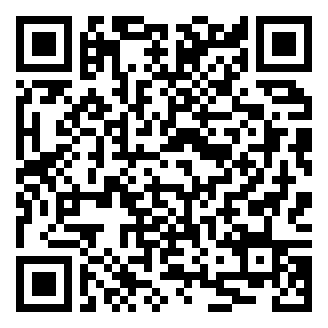

[ilyachichkanov.github.io/Reinforcement-learning/lecture05.html](https://ilyachichkanov.github.io/Reinforcement-learning/lecture05.html)

| | Раздел | Минут |
|---|---|---|
| 1 | 🔁 Ценности или вероятности: две семьи методов | 8 |
| 2 | Новая среда: коридор, где лучшая стратегия стохастическая | 14 |
| 3 | Стратегия с параметрами: softmax | 10 |
| 4 | Градиент по попыткам: три автомата | 15 |
| 5 | REINFORCE: от одного шага к эпизоду | 15 |
| 6 | Вычитаем среднее | 16 |
| 7 | ⏱ Value-based или policy-based | 6 |
| 8 | Итоги и где это работает | 6 |

Пометки: **🔁** — вспоминаем пройденное, **⏱** — резерв, если останется время. Служебный код лежит в `pg_plots.py`: среда-коридор, точный расчёт ценности и рисовальщики; читать его не нужно.

In [1]:
# Служебный модуль лекции. Локально он уже в репозитории, в Google Colab — скачивается.
import pathlib, urllib.request
REPO = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main/"
if not pathlib.Path("pg_plots.py").exists():
    urllib.request.urlretrieve(REPO + "05-policy-gradient/lecture/pg_plots.py", "pg_plots.py")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pg_plots import *     # Corridor, corridor_value, softmax, BANDIT_MEANS и рисовальщики

## 1. 🔁 Ценности или вероятности: две семьи методов

Вспомним два метода, которые уже были в курсе.

* **Q-learning** (лекции 3 и 4) хранит таблицу оценок $Q(s, a)$. После обучения агент ходит по ней так же, как в домашке 2 при **проверке по таблице**: в каждом состоянии делает действие с наибольшим $Q$.
* **Cross-Entropy** (лекция 1) хранит сами **вероятности действий** $\pi(a \mid s)$ — частоты действий в элитных эпизодах — и выбирает действие по этим вероятностям.

**Вопрос 1 (голосуем).** Оба метода обучены. Агент 100 раз оказывается в одной и той же клетке. Что верно?

* **A.** по Q-learning он все 100 раз делает одно и то же действие, по Cross-Entropy — разные действия;
* **B.** наоборот: по Q-learning — разные действия, по Cross-Entropy — одно и то же;
* **C.** оба метода все 100 раз делают одно и то же действие;
* **D.** оба метода выбирают действия случайно.

Проверим на двух строках, которые вы уже видели. Строка таблицы $Q$ — из первого вопроса лекции 4: $Q(\leftarrow) = +0.10$, $Q(\downarrow) = -1.00$, $Q(\rightarrow) = +0.20$, $Q(\uparrow) = +0.40$. Строка вероятностей — стартовая клетка S озера после первой итерации Cross-Entropy в лекции 1 (раздел 12.4): $(0.14,\ 0.43,\ 0.14,\ 0.29)$ для $\leftarrow, \downarrow, \rightarrow, \uparrow$. По каждой строке сыграем 100 раз и посчитаем, сколько раз выпало каждое действие.

Q-learning, 100 раз:    ←   0  ↓   0  →   0  ↑ 100
Cross-Entropy, 100 раз: ←  14  ↓  34  →  15  ↑  37


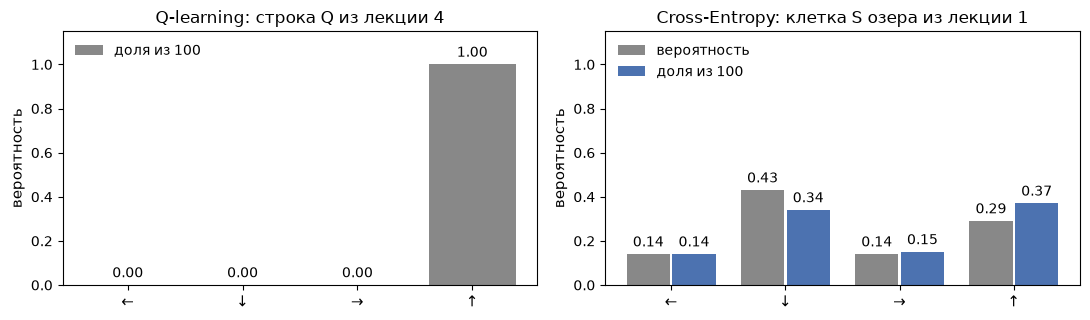

In [3]:
arrows = ["←", "↓", "→", "↑"]
q_row = np.array([+0.10, -1.00, +0.20, +0.40])    # строка таблицы Q из вопроса 1 лекции 4
cem_row = np.array([0.14, 0.43, 0.14, 0.29])       # клетка S озера после первой итерации Cross-Entropy (лекция 1)

rng = np.random.default_rng(0)
by_table = np.full(100, q_row.argmax())                 # проверка по таблице: каждый раз действие с наибольшим Q
by_probs = rng.choice(4, size=100, p=cem_row)            # Cross-Entropy: каждый раз случайно по вероятностям
count_table, count_probs = np.bincount(by_table, minlength=4), np.bincount(by_probs, minlength=4)
print("Q-learning, 100 раз:   ", "  ".join(f"{a} {n:3d}" for a, n in zip(arrows, count_table)))
print("Cross-Entropy, 100 раз:", "  ".join(f"{a} {n:3d}" for a, n in zip(arrows, count_probs)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
plot_probs({"доля из 100": count_table / 100}, ax=axes[0], labels=arrows, ylim=(0, 1.15),
           title="Q-learning: строка Q из лекции 4")
plot_probs({"вероятность": cem_row, "доля из 100": count_probs / 100}, ax=axes[1], labels=arrows, ylim=(0, 1.15),
           title="Cross-Entropy: клетка S озера из лекции 1")
plt.tight_layout(); plt.show()

Ответ **A**. По таблице Q-learning агент все 100 раз шагнул $\uparrow$ — у этого действия наибольшее $Q$. По вероятностям Cross-Entropy выпадали все четыре действия, с долями, близкими к вероятностям строки. Это два вида стратегий из лекций 1 и 3:

* **детерминированная** — в одном и том же состоянии всегда одно и то же действие; в таблице стратегии в каждой строке одна единица. Так ходит Q-learning по таблице;
* **стохастическая** — действие выбирается случайно по вероятностям $\pi(a \mid s)$. Так ходит Cross-Entropy.

Отсюда две семьи методов:

* **value-based** (Q-learning, SARSA) учат ценности, а стратегия получается из них выбором действия с наибольшей ценностью — она детерминированная;
* **policy-based** учат вероятности действий напрямую — стратегия стохастическая. Cross-Entropy — первый наш пример, сегодня будет второй, главный.

На обрыве и в такси детерминированной стратегии хватало: лучшая стратегия там и была детерминированной. Следующий раздел — среда, где лучшая стратегия стохастическая.

**Одной строкой:** value-based учат ценности и выбирают действие с наибольшей — стратегия детерминированная; policy-based учат вероятности действий — стратегия стохастическая.

## 2. Новая среда: коридор, где лучшая стратегия стохастическая

Во всех средах прошлых лекций агент знал, в какой он клетке. Так бывает не всегда: датчики видят не всё, и два разных места выглядят одинаково — как одинаковые двери в длинном коридоре для робота с камерой. Возьмём самую маленькую среду с такой трудностью — коридор из учебника Саттона и Барто (пример 13.1).

Описание по чек-листу:

* **состояние** — клетка 0, 1 или 2; старт в клетке 0, выход справа от клетки 2;
* **наблюдение** — одно и то же во всех клетках: датчик агента клеток не различает;
* **действия** — два: «влево» и «вправо»; в клетке 1 они **перепутаны**: «вправо» ведёт в клетку 0, «влево» — в клетку 2; «влево» из клетки 0 упирается в стену, агент остаётся на месте;
* **награда** — $-1$ за каждый шаг, $\gamma = 1$: ценность старта — это минус среднее число шагов до выхода;
* **конец эпизода** — выход.

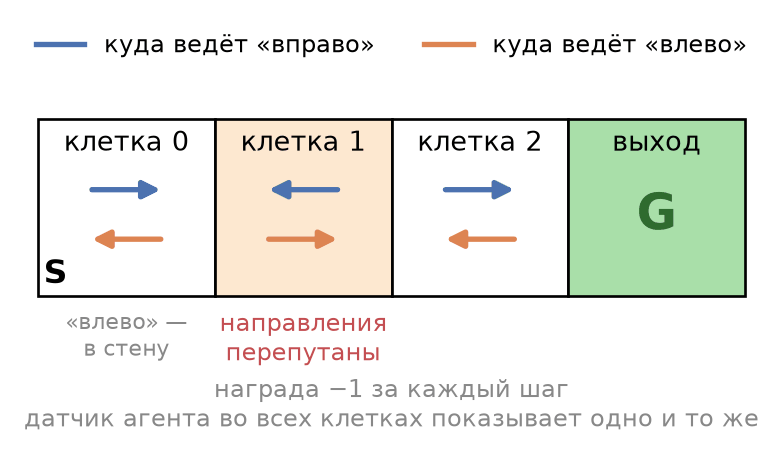

Раз наблюдение одно, стратегия агента — одно число: $p$ — **вероятность выбрать «вправо»**, одна и та же во всех клетках.

**Вопрос 2 (голосуем).** Какая стратегия в среднем доходит до выхода быстрее всех?

* **A.** всегда «вправо» ($p = 1$);
* **B.** $\varepsilon$-жадная с лучшим действием «вправо», $\varepsilon = 0.1$ ($p = 0.95$: в случайном шаге «вправо» выпадает в половине случаев);
* **C.** бросать монетку: «вправо» и «влево» поровну ($p = 0.5$);
* **D.** всегда «влево» ($p = 0$).

Сначала посмотрим на один эпизод с монеткой: что происходит на самом деле и что видит агент.

In [4]:
env = Corridor()
rng = np.random.default_rng(1)
obs, info = env.reset()
cells, observations = [info["cell"]], [obs]
while True:
    obs, r, terminated, truncated, info = env.step(int(rng.random() < 0.5))   # 1 = «вправо», 0 = «влево»
    cells.append(info["cell"]); observations.append(obs)
    if terminated:
        break
print("клетка на самом деле:", *cells)
print("что видит агент:     ", *observations)
print(f"шагов: {len(cells) - 1}, return: {-(len(cells) - 1)}")

клетка на самом деле: 0 0 0 1 2 3
что видит агент:      0 0 0 0 0 0
шагов: 5, return: -5


Агент видит одни нули — по наблюдению нельзя понять, где он. Теперь посчитаем ценность каждой стратегии **точно** — уравнением Беллмана для стратегии из лекции 2:

$$
V^\pi(s) \;=\; \sum_a \pi(a \mid s) \sum_{s'} P(s' \mid s, a)\,\big[\, r + \gamma\, V^\pi(s') \,\big] .
$$

Напомним обозначения: $s$ — состояние, $a$ — действие, $s'$ — следующее состояние, $\pi(a \mid s)$ — вероятность, что стратегия выберет $a$ в $s$, $P(s' \mid s, a)$ — вероятность, что после $a$ среда переведёт агента из $s$ в $s'$, $r$ — награда за этот шаг, $\gamma$ — коэффициент дисконтирования. В лекции 2 вероятность перехода писалась маленькой $p$; здесь пишем заглавную $P$, чтобы не путать её с нашим $p$ — вероятностью выбрать «вправо».

Подставим в уравнение коридор:

* состояние $s$ — номер клетки: 0, 1 или 2;
* переходы не случайные: действие из клетки $s$ всегда ведёт в одну и ту же клетку, поэтому $P(s' \mid s, a) = 1$ для неё и 0 для остальных, и сумма по $s'$ превращается в одно слагаемое;
* награда за любой шаг $r = -1$, $\gamma = 1$;
* $\pi(\text{«вправо»} \mid s) = p$ и $\pi(\text{«влево»} \mid s) = 1 - p$ во всех клетках.

Получается $V(s) = p\,\big[-1 + V(\text{куда ведёт «вправо» из } s)\big] + (1 - p)\,\big[-1 + V(\text{куда ведёт «влево» из } s)\big]$, то есть

$$
V(s) \;=\; -1 \;+\; p \cdot V(\text{куда ведёт «вправо» из } s) \;+\; (1 - p) \cdot V(\text{куда ведёт «влево» из } s) .
$$

Выпишем его для каждой клетки $s = 0, 1, 2$, глядя на картинку коридора; у выхода $V = 0$:

$$
\begin{aligned}
V(0) &= -1 + p \cdot V(1) + (1 - p) \cdot V(0) && \text{«вправо» — в клетку 1, «влево» — в стену, агент остаётся в 0} \\
V(1) &= -1 + p \cdot V(0) + (1 - p) \cdot V(2) && \text{направления перепутаны: «вправо» — в 0, «влево» — в 2} \\
V(2) &= -1 + p \cdot 0 + (1 - p) \cdot V(1) && \text{«вправо» — к выходу, «влево» — в клетку 1}
\end{aligned}
$$

Три линейных уравнения на три неизвестных $V(0), V(1), V(2)$. Для монетки $p = 0.5$ их можно решить руками. Из первого уравнения $0.5\,V(0) = -1 + 0.5\,V(1)$, то есть $V(0) = V(1) - 2$; из третьего $V(2) = -1 + 0.5\,V(1)$. Подставляем оба во второе:

$$
V(1) = -1 + 0.5\,\big(V(1) - 2\big) + 0.5\,\big(-1 + 0.5\,V(1)\big) = -2.5 + 0.75\,V(1) ,
$$

откуда $V(1) = -10$, $V(0) = -12$, $V(2) = -6$: с монеткой агент выходит из коридора в среднем за 12 шагов.

Те же подстановки для любого $p$: из первого уравнения $V(0) = V(1) - 1/p$, из третьего $V(2) = -1 + (1 - p)\,V(1)$, из второго $V(1) = -(3 - p)\,/\,\big(p\,(1 - p)\big)$, и ценность старта

$$
V(0) \;=\; -\,\frac{2\,(2 - p)}{p\,(1 - p)} .
$$

При $p \to 1$ и при $p \to 0$ знаменатель стремится к нулю, а ценность — к $-\infty$: детерминированная стратегия не выходит из коридора никогда.

В коде перенесём неизвестные в левую часть и решим систему $A\,V = b$ функцией `np.linalg.solve` — так же, как в семинаре 2 считалась точная ценность стратегии. Функция `corridor_values(p)` возвращает все три ценности; сверим её с ручным решением и с формулой. Та же система решается в `corridor_value(p)` из `pg_plots.py` — её используют рисовальщики.

In [5]:
def corridor_values(p):
    # три уравнения коридора в виде A·V = b; неизвестные V(0), V(1), V(2) перенесены в левую часть
    A = np.array([[p,   -p,        0.0     ],      #  p·V(0) − p·V(1)                = −1
                  [-p,   1.0,     -(1 - p) ],      # −p·V(0) + V(1) − (1 − p)·V(2)    = −1
                  [0.0, -(1 - p),  1.0     ]])     #          −(1 − p)·V(1) + V(2)    = −1
    b = np.array([-1.0, -1.0, -1.0])
    return np.linalg.solve(A, b)

print("p = 0.5: V(0), V(1), V(2) =", corridor_values(0.5).round(2) + 0.0)
for p in (0.05, 0.5, 0.95):
    print(f"p = {p:.2f}: система {corridor_values(p)[0]:7.2f}, формула {-2 * (2 - p) / (p * (1 - p)):7.2f}")

p = 0.5: V(0), V(1), V(2) = [-12. -10.  -6.]
p = 0.05: система  -82.11, формула  -82.11
p = 0.50: система  -12.00, формула  -12.00
p = 0.95: система  -44.21, формула  -44.21


A. всегда «вправо»     p = 1.00:   выхода нет никогда
B. ε-жадная «вправо»   p = 0.95:   ценность старта  -44.2
C. монетка             p = 0.50:   ценность старта  -12.0
D. всегда «влево»      p = 0.00:   выхода нет никогда
лучшая                 p = 0.586: ценность старта -11.66   (2 − √2 = 0.586)


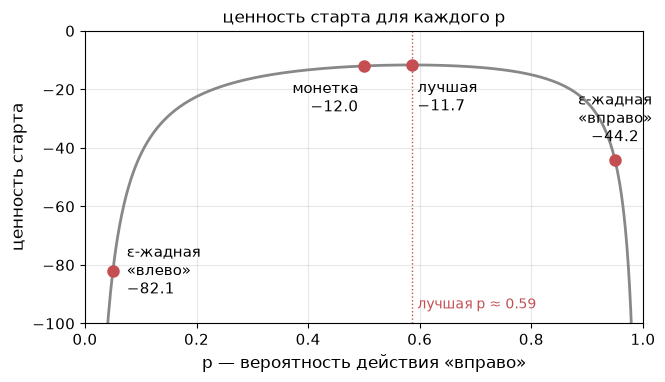

In [6]:
options = {"A. всегда «вправо»": 1.0, "B. ε-жадная «вправо»": 0.95, "C. монетка": 0.5, "D. всегда «влево»": 0.0}
for name, p in options.items():
    v = corridor_value(p)
    print(f"{name:22s} p = {p:4.2f}:  ", f"ценность старта {v:6.1f}" if np.isfinite(v) else "выхода нет никогда")

ps = np.linspace(0.001, 0.999, 9981)
values = np.array([corridor_value(p) for p in ps])
p_best = ps[values.argmax()]
print(f"{'лучшая':22s} p = {p_best:.3f}: ценность старта {values.max():6.2f}   (2 − √2 = {2 - np.sqrt(2):.3f})")

plot_value_curve({"ε-жадная\n«вправо»": 0.95, "ε-жадная\n«влево»": 0.05, "монетка": 0.5, "лучшая": p_best},
                 title="ценность старта для каждого p")
plt.show()

Ответ **C**: с монеткой агент тратит в среднем 12 шагов (ценность $-12$), с $\varepsilon$-жадной стратегией — 44, почти вчетверо больше. «Всегда вправо» и «всегда влево» не доходят до выхода никогда. Лучшая стратегия — $p = 2 - \sqrt{2} \approx 0.586$, где формула достигает максимума: ценность $-11.66$, лишь немного лучше монетки.

**Почему так выходит.** «Вправо» из клетки 0 ведёт в клетку 1, а там «вправо» возвращает в клетку 0 — агент ходит по кругу без конца. Чтобы выйти, в клетке 1 нужно сделать «влево», а в клетках 0 и 2 — «вправо». Клеток агент не различает, поэтому «влево» в клетке 1 может выпасть только случайно. У $\varepsilon$-жадной стратегии «влево» выпадает 1 раз из 20, и каждая неудача стоит двух шагов — в клетку 0 и обратно: около $20 \cdot 2 = 40$ шагов только на клетку 1, отсюда $-44$. Монетка в клетке 1 угадывает в половине случаев, зато чаще ошибается в клетках 0 и 2; лучший баланс — $p \approx 0.59$.

Может ли Q-learning научиться такой стратегии? Проверим. Наблюдение одно, поэтому таблица — две оценки: $Q(\text{влево})$ и $Q(\text{вправо})$. Учим 1000 эпизодов с $\varepsilon = 0.1$ и $\alpha = 0.1$ — это Q-learning лекции 3 без изменений, только таблица из одной строки.

In [7]:
def q_learning_corridor(n_episodes=1000, eps=0.1, alpha=0.1, seed=0, max_steps=1000):
    # Q-learning лекции 3; наблюдение одно, поэтому таблица — две оценки: Q[0] = «влево», Q[1] = «вправо»
    rng = np.random.default_rng(seed)
    env, Q = Corridor(), np.zeros(2)
    for _ in range(n_episodes):
        env.reset()
        for _ in range(max_steps):
            a = int(rng.integers(2)) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q == Q.max())))
            _, r, terminated, _, _ = env.step(a)
            Q[a] += alpha * (r + (0.0 if terminated else Q.max()) - Q[a])
            if terminated:
                break
    return Q

for seed in range(3):
    Q = q_learning_corridor(seed=seed)
    print(f"сид {seed}: Q(влево) = {Q[0]:6.1f}, Q(вправо) = {Q[1]:6.1f}  ->  по таблице «{'вправо' if Q[1] > Q[0] else 'влево'}»")

env = Corridor(); env.reset()
steps = 0
while steps < 1000:                       # проверка по таблице: всегда «вправо», не больше 1000 шагов
    _, _, terminated, _, _ = env.step(1); steps += 1
    if terminated:
        break
print(f"проверка по таблице: {'дошёл' if terminated else 'не дошёл'} за {steps} шагов")
print(f"с ε = 0.1 во время проверки (p = 0.95): ценность старта {corridor_value(0.95):.1f}")
print(f"ε, при котором ε-жадная стратегия совпала бы с лучшей: {2 * (1 - p_best):.2f}")

сид 0: Q(влево) =  -23.0, Q(вправо) =  -19.2  ->  по таблице «вправо»


сид 1: Q(влево) =  -23.1, Q(вправо) =  -20.8  ->  по таблице «вправо»


сид 2: Q(влево) =  -24.8, Q(вправо) =  -21.1  ->  по таблице «вправо»
проверка по таблице: не дошёл за 1000 шагов
с ε = 0.1 во время проверки (p = 0.95): ценность старта -44.2
ε, при котором ε-жадная стратегия совпала бы с лучшей: 0.83


На всех трёх запусках у «вправо» оценка выше, и по таблице агент ходит по кругу между клетками 0 и 1. Выходит он только благодаря случайным шагам $\varepsilon$-жадности — в среднем за 44 шага.

Почему Q-learning не находит лучшую стратегию. По таблице он в каждой клетке выбирает одно действие — с наибольшим $Q$. Клетки коридора неразличимы, значит, это одно действие на весь коридор. Выбирать «вправо» с вероятностью 0.59 таблица ценностей не умеет: случайные шаги в ней даёт только $\varepsilon$, а $\varepsilon$ задаёт человек. Подобрать его руками можно — при $\varepsilon \approx 0.83$ $\varepsilon$-жадная стратегия совпала бы с лучшей, — но это подбор, а не обучение; в среде, где нужная доля случайных шагов своя в каждом месте, руками её не подобрать.

**Одной строкой:** если агент не различает состояния, лучшая стратегия бывает стохастической, а Q-learning по таблице даёт только детерминированную. Нужен метод, который учит саму вероятность $p$.

## 3. Стратегия с параметрами: softmax

Учить вероятности напрямую — значит понемногу сдвигать их в лучшую сторону. Сдвигать сами вероятности неудобно: они должны оставаться между 0 и 1 и в сумме давать 1. Поэтому каждому действию $a$ дают число $\theta_a$ — **предпочтение**; оно может быть любым: положительным, отрицательным, нулём. Вектор $\theta$ — это предпочтения всех действий, по одному числу на действие. Вероятности из предпочтений получают формулой **softmax**:

$$
\pi(a) \;=\; \frac{e^{\theta_a}}{\sum_b e^{\theta_b}} .
$$

Здесь $a$ — действие, вероятность которого мы считаем, а $b$ — индекс суммирования: сумма в знаменателе идёт по **всем** действиям, включая само $a$. Для трёх действий A, B, C формула распадается на три дроби с одним и тем же знаменателем:

$$
\pi(A) = \frac{e^{\theta_A}}{e^{\theta_A} + e^{\theta_B} + e^{\theta_C}}, \qquad
\pi(B) = \frac{e^{\theta_B}}{e^{\theta_A} + e^{\theta_B} + e^{\theta_C}}, \qquad
\pi(C) = \frac{e^{\theta_C}}{e^{\theta_A} + e^{\theta_B} + e^{\theta_C}} .
$$

Числители положительны при любых $\theta$, а сумма трёх дробей — это знаменатель, делённый сам на себя, то есть 1. Значит, при любых предпочтениях получаются настоящие вероятности. Большее предпочтение даёт большую вероятность, а малое изменение $\theta$ — малое изменение $\pi$. Это та же формула, что на выходе классификатора в ноутбуке `dl_basics`.

Пример руками: $\theta = (1, 0, 0)$. Тогда $e^1 \approx 2.72$, $e^0 = 1$, знаменатель $2.72 + 1 + 1 = 4.72$, и $\pi(A) = 2.72 / 4.72 \approx 0.58$, $\pi(B) = \pi(C) = 1 / 4.72 \approx 0.21$.

In [8]:
print("θ = (0, 0, 0)  ->  π =", softmax([0.0, 0.0, 0.0]).round(2))
print("θ = (1, 0, 0)  ->  π =", softmax([1.0, 0.0, 0.0]).round(2))

θ = (0, 0, 0)  ->  π = [0.33 0.33 0.33]
θ = (1, 0, 0)  ->  π = [0.58 0.21 0.21]


В коридоре действий два — «влево» и «вправо», — значит, и предпочтений два: $\theta_{\leftarrow}$ у «влево» и $\theta_{\rightarrow}$ у «вправо». Вероятность «вправо» по той же формуле:

$$
p \;=\; \frac{e^{\theta_{\rightarrow}}}{e^{\theta_{\leftarrow}} + e^{\theta_{\rightarrow}}} .
$$

Но одно из двух чисел здесь лишнее. Если прибавить к обоим предпочтениям одно и то же число $c$, числитель и знаменатель умножатся на $e^{c}$, и $p$ не изменится: вероятности зависят только от **разности** предпочтений. Проверим числом: предпочтения $(0, 1)$ и $(5, 6)$ должны дать одно и то же $p$.

In [9]:
print("(θ_←, θ_→) = (0, 1)  ->  p =", softmax([0.0, 1.0])[1].round(3))
print("(θ_←, θ_→) = (5, 6)  ->  p =", softmax([5.0, 6.0])[1].round(3))

(θ_←, θ_→) = (0, 1)  ->  p = 0.731
(θ_←, θ_→) = (5, 6)  ->  p = 0.731


Поэтому предпочтение «влево» закрепим нулём, $\theta_{\leftarrow} = 0$, а предпочтение «вправо» будем обозначать просто $\theta$. Вектор предпочтений коридора — $(0, \theta)$, и

$$
p \;=\; \frac{e^{\theta}}{e^{0} + e^{\theta}} \;=\; \frac{e^{\theta}}{1 + e^{\theta}} .
$$

Одно число $\theta$ задаёт всю стратегию: при $\theta = 0$ получается $p = 0.5$, при большом положительном $\theta$ агент почти всегда идёт «вправо», при большом отрицательном — почти всегда «влево». В коде это `softmax([0.0, theta])[1]` — вероятность второго действия, «вправо».

In [10]:
for theta in (-3.0, 0.0, 0.35, 3.0):
    print(f"коридор, θ = {theta:+.2f}  ->  p = {softmax([0.0, theta])[1]:.3f}")

коридор, θ = -3.00  ->  p = 0.047
коридор, θ = +0.00  ->  p = 0.500
коридор, θ = +0.35  ->  p = 0.587
коридор, θ = +3.00  ->  p = 0.953


Теперь главное: как сделать **сыгранное** действие вероятнее. Смотреть будем на $\log \pi(a)$: он растёт вместе с $\pi(a)$, а формула для него проще. Узнаем, как $\log \pi(a)$ меняется при сдвиге каждого предпочтения, прямо числом: сдвинем $\theta_b$ на 0.001 и поделим изменение на 0.001. Это **наклон** $\log\pi(a)$ по $\theta_b$; вектор наклонов по всем $\theta_b$ — градиент $\nabla_\theta \log \pi(a)$.

Пример: три действия A, B, C с вероятностями $(0.5,\ 0.3,\ 0.2)$, сыграли B.

In [11]:
theta = np.log([0.5, 0.3, 0.2])          # такие предпочтения дают вероятности (0.5, 0.3, 0.2)
a, h = 1, 1e-3                           # сыграли действие B (номер 1)
slope = np.array([(np.log(softmax(theta + h * np.eye(3)[b])[a]) - np.log(softmax(theta)[a])) / h
                  for b in range(3)])
print("наклон log π(B) по θ_A, θ_B, θ_C:", slope.round(2))

наклон log π(B) по θ_A, θ_B, θ_C: [-0.5  0.7 -0.2]


**Вопрос 3 (голосуем).** Сдвинем предпочтения на половину этого наклона: $\theta \leftarrow \theta + 0.5 \cdot \text{наклон}$. Какие вероятности вырастут?

* **A.** только у B;
* **B.** у B и у A;
* **C.** у всех трёх;
* **D.** у B вырастет, у A и C не изменится.

было:  [0.5 0.3 0.2]
стало: [0.39 0.43 0.18]
e_B − π: [-0.5  0.7 -0.2]   — сравните с наклоном выше


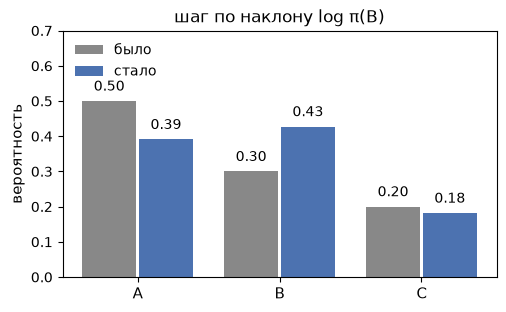

In [12]:
pi_before = softmax(theta)
pi_after = softmax(theta + 0.5 * slope)
print("было: ", pi_before.round(2))
print("стало:", pi_after.round(2))
print("e_B − π:", (np.eye(3)[a] - pi_before).round(2), "  — сравните с наклоном выше")
plot_probs({"было": pi_before, "стало": pi_after}, labels=["A", "B", "C"], ylim=(0, 0.7),
           title="шаг по наклону log π(B)")
plt.show()

Ответ **A**: B выросла с 0.30 до 0.43, а A и C уменьшились. Наклон совпал с вектором $e_B - \pi = (0, 1, 0) - (0.5,\ 0.3,\ 0.2)$, где $e_B$ — единица на месте сыгранного действия. Только теперь формула — из $\log \pi(a) = \theta_a - \log \sum_b e^{\theta_b}$:

$$
\frac{\partial \log \pi(a)}{\partial \theta_b} \;=\; [a = b] - \pi(b), \qquad\text{то есть}\qquad \nabla_\theta \log \pi(a) \;=\; e_a - \pi .
$$

Здесь $a$ — сыгранное действие, $b$ — действие, чьё предпочтение сдвигаем, а $[a = b]$ равно 1, если $b$ — то же самое действие $a$, и 0 для всех остальных.

У сыгранного действия предпочтение растёт на $1 - \pi(a)$, у остальных падает на свою вероятность $\pi(b)$: у A на 0.5 · 0.5 = 0.25, у C на 0.5 · 0.2 = 0.10. Поэтому A потеряла больше, чем C.

В коридоре у «вправо» предпочтение $\theta$, и та же формула даёт $\nabla_\theta \log \pi(a) = [a = \text{«вправо»}] - p$.

**Одной строкой:** шаг по $e_a - \pi$ поднимает вероятность сыгранного действия и забирает её у остальных пропорционально их вероятностям.

## 4. Градиент по попыткам: три автомата

Мы знаем, как сделать действие вероятнее. Осталось понять, **какое** действие и **насколько**. Начнём со среды без состояний — с игровых автоматов лекции 4. Автоматов три: №1 выигрывает в среднем 1, №2 — 2, №3 — 3, каждый раз со случайным шумом (стандартное отклонение 1). Стратегия — softmax по трём предпочтениям $\theta$. Цель — **средний выигрыш стратегии**

$$
J(\theta) \;=\; \sum_a \pi(a)\, \mu_a ,
$$

где $\mu_a$ — средний выигрыш автомата $a$. Чтобы поднять $J$, будем сдвигать $\theta$ туда, где $J$ растёт быстрее всего, — по наклону $\nabla_\theta J$. Если бы мы знали все $\mu_a$, наклон считался бы шевелением, как в разделе 3. Один раз подглядим в $\mu$ — чтобы было с чем сравнивать.

In [13]:
means = np.array(BANDIT_MEANS)            # средние выигрыши автоматов №1, №2, №3: 1, 2, 3
labels = ["№1", "№2", "№3"]

def J(theta):
    # средний выигрыш стратегии softmax(θ); агенту он неизвестен — считаем, чтобы было с чем сравнивать
    return softmax(theta) @ means

theta0, h = np.zeros(3), 1e-3              # равные вероятности
exact = np.array([(J(theta0 + h * np.eye(3)[b]) - J(theta0)) / h for b in range(3)])
print("точный наклон J по θ (подглядели в средние):", exact.round(2) + 0.0)

точный наклон J по θ (подглядели в средние): [-0.33  0.    0.33]


Наклон $(-0.33,\ 0,\ +0.33)$: предпочтение худшего автомата опустить, лучшего — поднять. Но средние выигрыши агенту неизвестны: он только играет. Вот как получить наклон из одних попыток: **сыграть автомат по стратегии, получить выигрыш $R$ и умножить его на $e_a - \pi$ из раздела 3.** Одна попытка — одна оценка наклона.

**Вопрос 4 (голосуем).** Вероятности равные, сыграли автомат №3 и выиграли $R = +3$. Чему равна оценка $R\,(e_a - \pi)$?

* **A.** $(-1,\ -1,\ +2)$;
* **B.** $(-0.33,\ 0,\ +0.33)$;
* **C.** $(0,\ 0,\ +3)$;
* **D.** $(+1,\ +1,\ +1)$.

In [14]:
pi0 = softmax(theta0)
print("одна оценка при a = №3, R = +3:", (3.0 * (np.eye(3)[2] - pi0)).round(2))

одна оценка при a = №3, R = +3: [-1. -1.  2.]


Ответ **A**: $3 \cdot \big((0, 0, 1) - (\tfrac13, \tfrac13, \tfrac13)\big) = (-1, -1, +2)$. На точный наклон (вариант B) одна оценка не похожа: в неё попал выигрыш только сыгранного автомата.

Проверим две вещи: совпадает ли с наклоном **среднее** многих оценок и насколько надёжна **одна**. Функция `estimates(n)` делает $n$ попыток и возвращает $n$ оценок (параметры `shift` и `baseline` понадобятся в разделе 6). Скажем, что оценка **указывает в гору**, если маленький шаг по ней поднимает средний выигрыш $J$. Функция `share_uphill(n_avg)` усредняет по `n_avg` оценок и считает, в какой доле повторов такое среднее указывает в гору.

среднее 100 000 оценок: [-0.34  0.    0.33]   точный наклон: [-0.33  0.    0.33]


усреднили попыток:    1  ->  оценка указывает в гору в 39% случаев
усреднили попыток:   10  ->  оценка указывает в гору в 86% случаев
усреднили попыток:  100  ->  оценка указывает в гору в 100% случаев
усреднили попыток: 1000  ->  оценка указывает в гору в 100% случаев


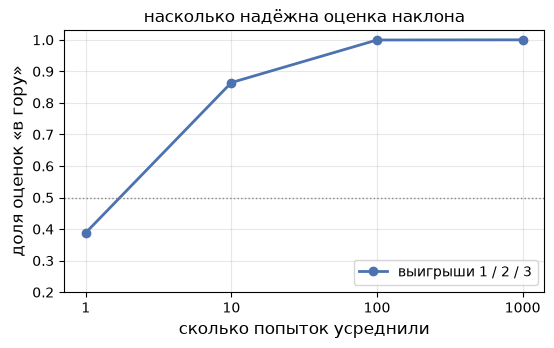

In [15]:
rng = np.random.default_rng(0)

def estimates(n, shift=0.0, baseline=0.0):
    # n оценок наклона по n попыткам: автомат выбирает стратегия, выигрыш — среднее + шум (+ shift)
    a = rng.choice(3, size=n, p=pi0)
    R = rng.normal(means[a], 1.0) + shift
    return (R - baseline)[:, None] * (np.eye(3)[a] - pi0)

def share_uphill(n_avg, shift=0.0, baseline=0.0, repeats=2000):
    # доля случаев, когда маленький шаг по среднему n_avg оценок поднимает средний выигрыш J
    g = estimates(n_avg * repeats, shift, baseline).reshape(repeats, n_avg, 3).mean(axis=1)
    return np.mean([J(theta0 + 1e-3 * gi) - J(theta0) > 1e-12 for gi in g])

print("среднее 100 000 оценок:", estimates(100_000).mean(axis=0).round(2) + 0.0, "  точный наклон:", exact.round(2) + 0.0)
ns = [1, 10, 100, 1000]
uphill_plain = [share_uphill(n) for n in ns]
for n, s in zip(ns, uphill_plain):
    print(f"усреднили попыток: {n:4d}  ->  оценка указывает в гору в {s:.0%} случаев")
plot_uphill(ns, {"выигрыши 1 / 2 / 3": uphill_plain}, title="насколько надёжна оценка наклона")
plt.show()

**В среднем** оценки совпадают с наклоном: среднее 100 000 попыток дало те же $(-0.33,\ 0,\ +0.33)$. А одна попытка указывает в гору лишь в 39 % случаев. Почему так мало: оценка по попытке автомата №3 указывает в гору; по попытке №2 — не меняет средний выигрыш; попытка №1 почти всегда приносит положительный выигрыш (ниже нуля шум уводит его в 16 % случаев), и оценка поднимает вероятность худшего автомата — указывает под гору. Итого $\tfrac13 + \tfrac13 \cdot 0.16 \approx 0.39$. Среднее десяти попыток указывает в гору в 86 % случаев, среднее ста — всегда.

Только теперь формула: почему среднее $R\,(e_a - \pi)$ равно наклону. Производная логарифма даёт $\nabla \pi(a) = \pi(a)\, \nabla \log \pi(a)$, и

$$
\nabla_\theta J \;=\; \sum_a \mu_a\, \nabla \pi(a) \;=\; \sum_a \pi(a)\, \mu_a\, \nabla \log \pi(a) \;=\; \mathbb{E}_{a \sim \pi}\big[\, R \; \nabla \log \pi(a) \,\big] .
$$

Сумма по автоматам с весами $\pi(a)$ — это среднее по попыткам, в которых автомат выбирает сама стратегия, а неизвестное $\mu_a$ заменяет сыгранный выигрыш $R$. Это **теорема о градиенте стратегии** (policy gradient theorem) в самом простом виде.

**Сведение к знакомому.** Шаг 3 Cross-Entropy в лекции 1 максимизировал $\sum_{\text{элита}} \log \pi(a \mid s)$ — это тот же сдвиг по $\nabla \log \pi$, только вес у элитной попытки 1, а у остальных 0. Градиент стратегии берёт весом сам выигрыш: хорошая попытка сдвигает стратегию сильнее средней, а не наравне с ней.

**Одной строкой:** наклон среднего выигрыша оценивается по попыткам — выигрыш, умноженный на $e_a - \pi$; одна оценка шумная, их среднее — точное.

## 5. REINFORCE: от одного шага к эпизоду

У автомата одна попытка — одно действие и одна награда. В эпизоде действий много, и каждому нужен свой вес. Какой? Действие на шаге $t$ не может повлиять на награды, полученные до него, — поэтому его вес — сумма наград **с шага $t$ до конца эпизода**:

$$
G_t \;=\; r_t + r_{t+1} + \dots + r_{T-1} ,
$$

где $r_k$ — награда за $k$-й шаг, $T$ — длина эпизода, $\gamma = 1$. Оценка наклона по одному эпизоду — сумма по его шагам, как в разделе 4:

$$
\widehat{\nabla J} \;=\; \sum_{t=0}^{T-1} G_t \; \nabla_\theta \log \pi(a_t \mid s_t) .
$$

Алгоритм **REINFORCE** (Уильямс, 1992) делает после каждого эпизода шаг по этой оценке: $\theta \leftarrow \theta + \alpha\, \widehat{\nabla J}$.

В коридоре $\nabla_\theta \log \pi(a_t) = [a_t = \text{«вправо»}] - p$ (раздел 3). Напишем две функции: `play(theta, rng)` играет эпизод стратегией с вероятностью «вправо» $p = e^{\theta} / (1 + e^{\theta})$ — вектор предпочтений $(0, \theta)$ из раздела 3 — и возвращает действия и награды, `grad_estimate(theta, actions, rewards)` считает $\widehat{\nabla J}$. Проверим тем же способом, что в разделе 4: среднее оценок по 2000 эпизодам против точного наклона кривой ценности из раздела 2; точный наклон считаем шевелением $\theta$ в функции `value_of(theta)` — ценности старта при данном $\theta$.

In [16]:
def play(theta, rng, max_steps=1000):
    # эпизод в коридоре: «вправо» с вероятностью p = softmax([0, θ])[1]; возвращает действия (1 = «вправо») и награды
    env, p = Corridor(), softmax([0.0, theta])[1]
    env.reset()
    actions, rewards = [], []
    for _ in range(max_steps):
        a = int(rng.random() < p)
        _, r, terminated, _, _ = env.step(a)
        actions.append(a); rewards.append(r)
        if terminated:
            break
    return np.array(actions), np.array(rewards)

def grad_estimate(theta, actions, rewards):
    # Σ_t G_t · ∇ log π(a_t); G_t — сумма наград с шага t до конца, ∇ log π(a_t) = [a_t = «вправо»] − p
    p = softmax([0.0, theta])[1]
    G = np.cumsum(rewards[::-1])[::-1]
    return np.sum(G * (actions - p))

def value_of(theta):
    return corridor_value(softmax([0.0, theta])[1])

rng = np.random.default_rng(0)
for theta in (-3.0, 0.0, 1.0):
    exact_slope = (value_of(theta + 1e-5) - value_of(theta - 1e-5)) / 2e-5
    g = np.array([grad_estimate(theta, *play(theta, rng)) for _ in range(2000)])
    print(f"θ = {theta:+.0f} (p = {softmax([0.0, theta])[1]:.2f}): наклон кривой {exact_slope:+6.1f}, "
          f"среднее 2000 оценок {g.mean():+6.1f}, разброс одной оценки ±{g.std():.0f}")

θ = -3 (p = 0.05): наклон кривой  +80.2, среднее 2000 оценок  +83.3, разброс одной оценки ±251
θ = +0 (p = 0.50): наклон кривой   +2.0, среднее 2000 оценок   +2.2, разброс одной оценки ±29
θ = +1 (p = 0.73): наклон кривой   -4.0, среднее 2000 оценок   -3.8, разброс одной оценки ±26


Среднее оценок совпадает с наклоном кривой с точностью до шума, а одна оценка разбросана на десятки и сотни единиц. Поэтому шаг берём маленьким.

Осталось собрать алгоритм: функция `reinforce` после каждого эпизода делает шаг $\theta \leftarrow \theta + \alpha \cdot$ `grad_estimate` и запоминает $p$ перед эпизодом. Запустим её десять раз с разными сидами.

**Вопрос 5 (голосуем).** Запускаем REINFORCE из $\theta = -3$: $p = 0.05$, ценность старта $-86$. Шаг $\alpha = 0.001$, 1000 эпизодов. Где окажется $p$?

* **A.** около 1 — «вправо» ведь чаще ведёт к выходу;
* **B.** около 0.95;
* **C.** около 0.59;
* **D.** около 0.5.

p после 1000 эпизодов, 10 запусков: [0.5  0.52 0.53 0.55 0.57 0.59 0.6  0.61 0.62 0.65]
ценность старта в конце: от -12.0 до -11.7   (лучшая -11.66)
эпизодов до ценности выше −13: [42, 97, 130, 132, 138, 145, 160, 196, 238, 298]


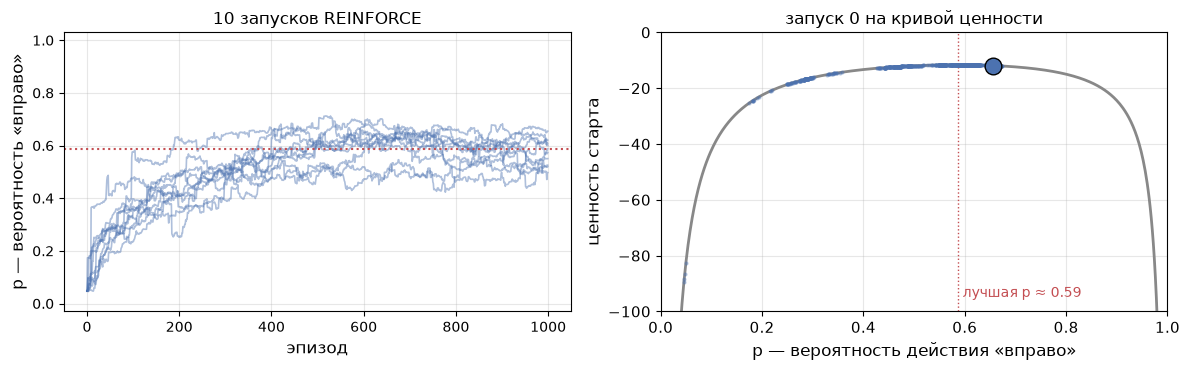

шаг α = 0.01: в 5 из 10 запусков p ушло к 0 или 1


In [17]:
def reinforce(theta=-3.0, alpha=0.001, n_episodes=1000, seed=0):
    # REINFORCE в коридоре; возвращает p перед каждым эпизодом
    rng = np.random.default_rng(seed)
    history = []
    for _ in range(n_episodes):
        history.append(softmax([0.0, theta])[1])
        actions, rewards = play(theta, rng)
        theta += alpha * grad_estimate(theta, actions, rewards)
    return np.array(history)

runs = np.array([reinforce(seed=s) for s in range(10)])
final = runs[:, -1]
reached = [int(np.argmax([corridor_value(p) > -13 for p in run])) for run in runs]
print("p после 1000 эпизодов, 10 запусков:", np.sort(final).round(2))
print(f"ценность старта в конце: от {min(map(corridor_value, final)):.1f} до {max(map(corridor_value, final)):.1f}"
      f"   (лучшая {corridor_value(p_best):.2f})")
print("эпизодов до ценности выше −13:", sorted(reached))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_seeds(runs, ax=axes[0], ylabel="p — вероятность «вправо»", xlabel="эпизод", title="10 запусков REINFORCE")
axes[0].axhline(p_best, color=C_ACCENT, ls=":", lw=1.5)
plot_value_curve(ax=axes[1], trail=runs[0], marker=runs[0, -1], title="запуск 0 на кривой ценности")
plt.tight_layout(); plt.show()

big_step = np.array([reinforce(alpha=0.01, seed=s)[-1] for s in range(10)])
stuck = int(np.sum((big_step < 0.01) | (big_step > 0.99)))
print(f"шаг α = 0.01: в {stuck} из 10 запусков p ушло к 0 или 1")

Ответ **C**: все десять запусков пришли к вершине кривой — $p$ от 0.50 до 0.65, ценность старта от $-12.0$ до $-11.7$ при лучшей $-11.66$. Это стохастическая стратегия, которую Q-learning по таблице дать не может. Вот как запуск 0 идёт по кривой ценности:

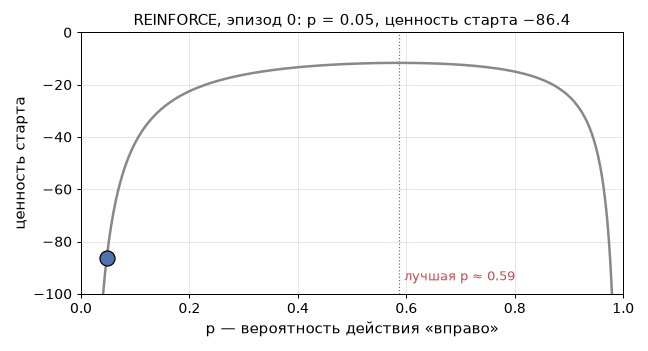

**Почему так выходит.** Средний шаг REINFORCE — наклон кривой ценности: это мы только что проверили числом. Слева от вершины кривая растёт — и $p$ увеличивается; справа падает — и $p$ уменьшается; в вершине наклон равен нулю, там $p$ и останавливается. Вершина пологая: при $p$ от 0.50 до 0.65 ценность хуже лучшей меньше чем на полшага, поэтому шум отдельных эпизодов и разносит запуски вдоль неё. Ответ A — ловушка: «вправо» действительно нужно чаще, но не всегда.

С шагом $\alpha = 0.01$ сорвалась половина запусков — 5 из 10: шумная оценка одного длинного эпизода выбросила $p$ к 0 или к 1, где выхода нет, и обучение остановилось. К выбору шага мы вернёмся в теме PPO.

**Одной строкой:** REINFORCE после каждого эпизода сдвигает $\theta$ на $\alpha \sum_t G_t \nabla \log \pi(a_t \mid s_t)$; в коридоре он находит лучшую стохастическую стратегию $p \approx 0.59$.

## 6. Вычитаем среднее

Вернёмся к трём автоматам и прибавим ко всем выигрышам по 100: теперь автоматы дают в среднем +101, +102 и +103. Лучший по-прежнему №3, разница между автоматами та же.

**Вопрос 6 (голосуем).** Вероятности равные, сыграли худший автомат №1 и выиграли +101. Что шаг REINFORCE с $\alpha = 0.01$ сделает с вероятностью автомата №1?

* **A.** вырастет;
* **B.** упадёт;
* **C.** не изменится;
* **D.** зависит от $\alpha$.

было:  [0.33 0.33 0.33]
стало: [0.58 0.21 0.21]


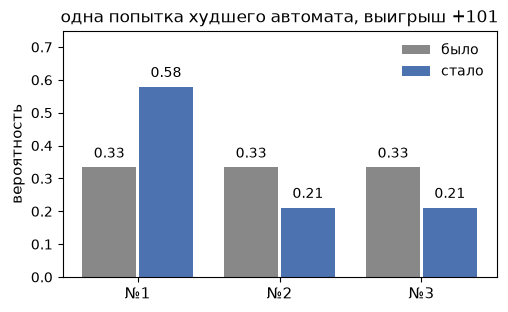

In [18]:
a, R, alpha = 0, 101.0, 0.01                         # сыграли автомат №1, выиграли +101
theta_new = theta0 + alpha * R * (np.eye(3)[a] - pi0)
print("было: ", pi0.round(2))
print("стало:", softmax(theta_new).round(2))
plot_probs({"было": pi0, "стало": softmax(theta_new)}, labels=labels, ylim=(0, 0.75), legend_loc="upper right",
           title="одна попытка худшего автомата, выигрыш +101")
plt.show()

Ответ **A**: после одной попытки вероятность худшего автомата выросла с 0.33 до 0.58. Ошибки в формуле нет: с выигрышами 1/2/3 было то же самое — попытка №1 поднимала худший автомат, и одна оценка указывала в гору лишь в 39 % случаев (раздел 4), а верным оказывалось среднее. Вопрос в том, насколько это мешает учиться.

Проверим опытом. Функция `bandit_reinforce` — REINFORCE на автоматах: после каждой попытки сдвиг $\theta \leftarrow \theta + \alpha\, R\, (e_a - \pi)$; она возвращает вероятности всех трёх автоматов после каждой попытки. Функция `summary` печатает медиану вероятности лучшего автомата №3 в конце и считает, на каком автомате закрепился каждый запуск — у какого вероятность в конце наибольшая. Шаг $\alpha = 0.01$, 2000 попыток, 20 запусков. Различие ровно одно — +100 ко всем выигрышам. Параметр `baseline` пока выключен — он понадобится чуть ниже.

выигрыши 1 / 2 / 3:       P(№3) в конце: медиана 0.97; закрепились на №1 / №2 / №3: 0 / 0 / 20
выигрыши 101 / 102 / 103: P(№3) в конце: медиана 0.00; закрепились на №1 / №2 / №3: 8 / 7 / 5


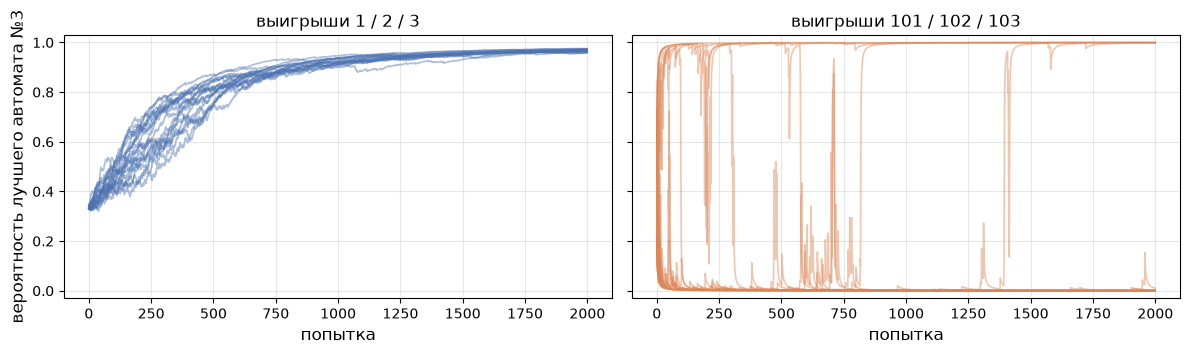

In [19]:
def bandit_reinforce(means, alpha=0.01, n_steps=2000, seed=0, baseline=False):
    # REINFORCE на автоматах; возвращает вероятности всех автоматов после каждой попытки: массив (n_steps, 3)
    rng = np.random.default_rng(seed)
    theta, b, history = np.zeros(len(means)), 0.0, []
    for n in range(1, n_steps + 1):
        pi = softmax(theta)
        a = rng.choice(len(means), p=pi)
        R = rng.normal(means[a], 1.0)
        b += (R - b) / n                             # среднее на ходу (лекция 3): средний выигрыш всех попыток
        weight = R - b if baseline else R
        theta += alpha * weight * (np.eye(len(means))[a] - pi)
        history.append(softmax(theta))
    return np.array(history)

def summary(runs):
    # runs — массив (запуски, попытки, 3): вероятность №3 в конце и на каком автомате закрепился каждый запуск
    winners = np.bincount(runs[:, -1].argmax(axis=1), minlength=3)
    return (f"P(№3) в конце: медиана {np.median(runs[:, -1, 2]):.2f}; "
            f"закрепились на №1 / №2 / №3: {winners[0]} / {winners[1]} / {winners[2]}")

plain = np.array([bandit_reinforce(means, seed=s) for s in range(20)])
shifted = np.array([bandit_reinforce(means + 100, seed=s) for s in range(20)])
print("выигрыши 1 / 2 / 3:      ", summary(plain))
print("выигрыши 101 / 102 / 103:", summary(shifted))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
plot_seeds(plain[:, :, 2], ax=axes[0], ylabel="вероятность лучшего автомата №3", title="выигрыши 1 / 2 / 3")
plot_seeds(shifted[:, :, 2], ax=axes[1], color=C_REWARD, title="выигрыши 101 / 102 / 103")
plt.tight_layout(); plt.show()

С выигрышами 1/2/3 все двадцать запусков находят лучший автомат. С выигрышами 101/102/103 — тот же алгоритм, тот же шаг — лучший нашли только 5 запусков из 20, а 8 закрепились на **худшем** автомате №1: каждый запуск остался на том автомате, который случайно вырвался вперёд.

**Почему так выходит.** Одна попытка сдвигает предпочтение сыгранного автомата на $\alpha \cdot R \cdot (1 - \pi) = 0.01 \cdot 101 \cdot 0.67 \approx 0.67$, каким бы автомат ни был. Разница между автоматами — одна единица выигрыша — добавляет к этому сдвигу $0.01 \cdot 1 \cdot 0.67 \approx 0.007$, в сто раз меньше. Автомат, который случайно сыграли несколько раз в начале, вырывается вперёд; его играют чаще, и его вероятность растёт дальше. Направление в среднем по-прежнему верное, но чтобы разглядеть его за такими скачками, нужны тысячи попыток.

Исправление — **вычитать среднее**: весом попытки служит не $R$, а $R - b$, где $b$ — средний выигрыш всех попыток до сих пор (среднее на ходу из лекции 3). Выигрыш хуже среднего опускает вероятность сыгранного автомата, лучше — поднимает. Тот же опыт, различие — только вычитание (`baseline=True`). Заодно посмотрим, как вычитание меняет одну оценку наклона из раздела 4: там вычитаем средний выигрыш стратегии, 102.

выигрыши 101 / 102 / 103, вычитаем среднее: P(№3) в конце: медиана 0.97; закрепились на №1 / №2 / №3: 0 / 0 / 20
одна оценка наклона, выигрыши 101 / 102 / 103, без вычитания: разброс ±48.09
одна оценка наклона, выигрыши 101 / 102 / 103, вычитаем 102: разброс ±0.54


усреднили попыток:    1  ->  в гору без вычитания 33%, с вычитанием 57%
усреднили попыток:   10  ->  в гору без вычитания 58%, с вычитанием 99%
усреднили попыток:  100  ->  в гору без вычитания 52%, с вычитанием 100%
усреднили попыток: 1000  ->  в гору без вычитания 59%, с вычитанием 100%


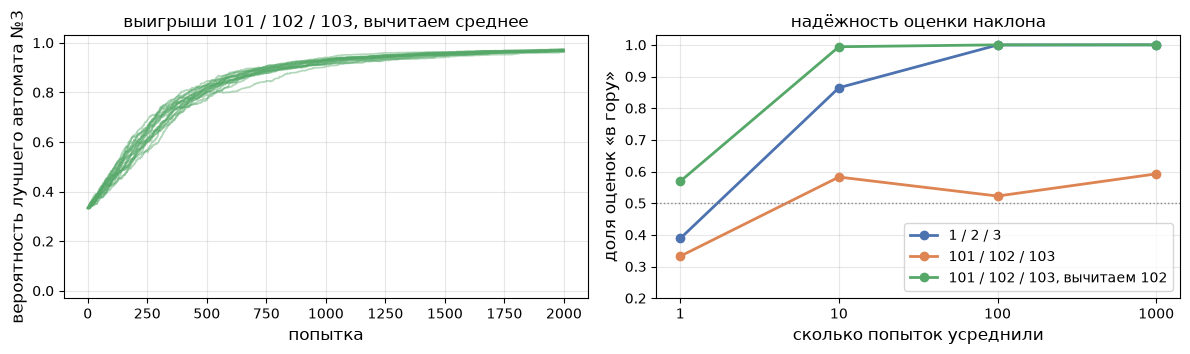

In [20]:
centered = np.array([bandit_reinforce(means + 100, seed=s, baseline=True) for s in range(20)])
print("выигрыши 101 / 102 / 103, вычитаем среднее:", summary(centered))

for name, base in (("без вычитания", 0.0), ("вычитаем 102", 102.0)):
    print(f"одна оценка наклона, выигрыши 101 / 102 / 103, {name}: разброс ±{estimates(100_000, 100, base).std(axis=0).mean():.2f}")
uphill_shift = [share_uphill(n, shift=100) for n in ns]
uphill_centered = [share_uphill(n, shift=100, baseline=102) for n in ns]
for n, s1, s2 in zip(ns, uphill_shift, uphill_centered):
    print(f"усреднили попыток: {n:4d}  ->  в гору без вычитания {s1:.0%}, с вычитанием {s2:.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_seeds(centered[:, :, 2], ax=axes[0], color=C_ENV, ylabel="вероятность лучшего автомата №3",
           title="выигрыши 101 / 102 / 103, вычитаем среднее")
plot_uphill(ns, {"1 / 2 / 3": uphill_plain, "101 / 102 / 103": uphill_shift,
                 "101 / 102 / 103, вычитаем 102": uphill_centered}, ax=axes[1], title="надёжность оценки наклона")
plt.tight_layout(); plt.show()

С вычитанием все двадцать запусков снова находят лучший автомат — как будто никаких +100 не было. Справа видно почему: без вычитания одна оценка указывает в гору в 33 % случаев, и даже среднее тысячи оценок — лишь в 59 %; с вычитанием среднее десяти оценок указывает в гору в 99 % случаев.

Только теперь формула: почему вычитание не портит средний шаг. Для любого числа $b$, которое не зависит от выбранного действия,

$$
\mathbb{E}_{a \sim \pi}\big[\, b\, \nabla \log \pi(a) \,\big] \;=\; b \sum_a \pi(a)\, \nabla \log \pi(a) \;=\; b \sum_a \nabla \pi(a) \;=\; b\, \nabla \sum_a \pi(a) \;=\; b\, \nabla 1 \;=\; 0 .
$$

Средний шаг тот же, а разброс одной оценки упал с ±48 до ±0.54 — почти в сто раз. В REINFORCE для эпизодов то же самое: вес шага — $G_t - b$.

Где это встречается:

* **CartPole** даёт $+1$ за каждый шаг — все награды положительны, это ровно случай «+100»: без вычитания REINFORCE поднимает вероятность любого сыгранного действия. Проверим на семинаре.
* **Cross-Entropy**: порог элиты работает как $b$ — эпизоды ниже порога получают вес 0.
* **Лучшее $b$ для каждого состояния — его ценность $V(s)$.** Тогда вес $G_t - V(s_t)$ говорит, насколько действие лучше обычного для этого состояния. Так устроен actor-critic (неделя 9): стратегия плюс оценка ценности.
* **Дообучение языковых моделей** методом GRPO: на один вопрос модель пишет несколько ответов, и из оценки каждого ответа вычитают среднюю оценку этих ответов (и делят на их разброс) — это и есть $R - b$.

**Одной строкой:** вычитай из выигрыша средний — средний шаг не меняется, а разброс оценки резко падает.

## 7. ⏱ Value-based или policy-based

| | value-based (Q-learning, SARSA) | policy-based (REINFORCE) |
|---|---|---|
| что учим | ценности $Q(s,a)$ | вероятности $\pi(a \mid s)$ через предпочтения $\theta$ |
| какая стратегия получается | детерминированная: действие с наибольшим $Q$ | любая — и детерминированная, и стохастическая |
| лучшая стратегия стохастическая (коридор) | по таблице её не получить | находит, $p \approx 0.59$ |
| непрерывные действия (усилие в суставе робота) | на каждом шаге нужен $\max_a Q(s,a)$ по непрерывному $a$ — отдельная задача оптимизации | стратегия выдаёт распределение действий, например нормальное: среднее и разброс |
| чьи данные | Q-learning учится и по чужому логу (off-policy, лекция 4) | только свежие эпизоды своей стратегии (on-policy): после шага старые эпизоды — уже про другую стратегию |
| когда учится | на каждом шаге (TD) | после конца эпизода, оценка шумная |

Дальше в курсе эти семьи сойдутся: actor-critic берёт у policy-based саму стратегию, а у value-based — оценку ценности, которую вычитает как $b$.

**Одной строкой:** policy-based методы выражают любые стратегии и непрерывные действия, но платят шумом и on-policy данными.

## 8. Итоги и где это работает

1. **Две семьи методов.** Value-based учат ценности и выбирают действие с наибольшей — стратегия детерминированная; policy-based учат сами вероятности действий — стратегия стохастическая.
2. **Лучшая стратегия бывает стохастической.** В коридоре, где агент не различает клеток, ценность старта $V(0) = -2(2 - p)/(p(1 - p))$: монетка набирает $-12$, $\varepsilon$-жадная стратегия — $-44$, детерминированная не доходит до выхода никогда.
3. **Градиент стратегии оценивается по попыткам:** $\nabla J = \mathbb{E}\big[R\, \nabla \log \pi(a)\big]$, для softmax $\nabla \log \pi(a) = e_a - \pi$. Cross-Entropy — тот же сдвиг с весом 0/1.
4. **REINFORCE**: после эпизода $\theta \leftarrow \theta + \alpha \sum_t G_t\, \nabla \log \pi(a_t \mid s_t)$, где $G_t$ — награды с шага $t$ до конца. В коридоре он находит $p \approx 0.59$.
5. **Вычитай среднее.** Вес $R - b$ не меняет средний шаг, но убирает разброс: при наградах около +100 без вычитания REINFORCE закрепляется на случайном автомате, с вычитанием находит лучший.

**Где это работает в жизни.**

* **Языковые модели.** Дообучение по оценкам ответов — градиент стратегии: стратегия — модель, действие — следующий токен, награда — оценка ответа. В методе GRPO вычитание среднего по ответам на один вопрос — ровно наш раздел 6.
* **Роботы.** Ходьба и манипуляция — непрерывные действия; стратегия выдаёт распределение усилий, и учат её методами этой семьи (PPO, неделя 10).
* **Игры.** В AlphaGo сеть-стратегию дообучали градиентом стратегии на партиях против её же прежних версий.

Словарь лекции: **value-based, policy-based, стратегия с параметрами, предпочтения $\theta$, softmax, градиент стратегии, $\nabla \log \pi$, теорема о градиенте стратегии, REINFORCE, $G_t$ (награды до конца эпизода), вычитание среднего (baseline)**.

## Литература

* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., глава 13 «Policy Gradient Methods»; коридор — пример 13.1. [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* Williams R. J. *Simple statistical gradient-following algorithms for connectionist reinforcement learning*. Machine Learning, 1992 — статья, где появился REINFORCE.
* OpenAI Spinning Up, «Intro to Policy Optimization» — тот же вывод с кодом на PyTorch: [spinningup.openai.com](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem) — раздел про policy gradient.

## На семинаре и дома

* **Квиз недели 5** — на [странице квизов](https://ilyachichkanov.github.io/Reinforcement-learning/), в зачётном режиме.
* **Домашка 2** — дедлайн 3 ноября, 23:59 МСК.
* **На семинаре** REINFORCE пишем своими руками: на обрыве против Cross-Entropy и на CartPole — с вычитанием среднего и без.